# Interpretowalność modeli (XAI)

**Plan notatnika:**
1. Po co wyjaśniać modele
2. Dane i model
3. Ważność cech z lasu losowego
4. Ważność permutacyjna
5. Wykresy częściowej zależności (PDP)
6. SHAP – idea
7. SHAP – interpretacja globalna
8. SHAP – interpretacja lokalna (pojedynczy klient)
9. LIME – alternatywne wyjaśnienie lokalne
10. XAI jako narzędzie do wykrywania błędów
11. Pułapki i dobre praktyki
12. Podsumowanie

## 1. Po co wyjaśniać modele

W rozdziale 4.2 zobaczyliśmy, że las losowy działa wyraźnie lepiej niż pojedyncze drzewo, ale ma jedną wadę: składa się z setek drzew, więc **nie da się go „przeczytać”** tak jak pojedynczego drzewa (rozdział 4.1) czy współczynników regresji (rozdziały 3.1 i 3.2). Takie modele nazywamy **czarnymi skrzynkami** (*black box*).

**XAI** (*Explainable AI*, wyjaśnialna sztuczna inteligencja) to zestaw metod, które pozwalają zajrzeć do czarnej skrzynki. Wyjaśnienia są potrzebne, żeby:
- **sprawdzić, czy model uczy się sensownych zależności** (a nie np. błędu w danych),
- **wykryć błędy**, np. wyciek danych (rozdział 4.4),
- **zdobyć zaufanie** użytkowników i spełnić wymogi prawne (np. klient ma prawo zapytać, dlaczego odmówiono mu kredytu),
- **wyciągnąć wnioski biznesowe** (co wpływa na odejścia klientów?).

### Wyjaśnianie modeli: dwa wymiary

| | **Globalne** | **Lokalne** |
|---|---|---|
| Pytanie | „Co jest ważne dla modelu **w ogóle**?” | „Dlaczego model podjął **taką** decyzję dla **tego** klienta?” |
| Przykład | wpływ liczby rozmów z obsługą na odejścia we wszystkich danych | dlaczego konkretny klient dostał 99% szans na odejście |

### Modele interpretowalne z natury i metody uniwersalne

Część modeli da się zrozumieć bez dodatkowych narzędzi: **regresja** (współczynniki), **płytkie drzewo decyzyjne** (reguły „jeśli…, to…”). Dla złożonych modeli (las losowy, gradient boosting, sieci neuronowe) używamy metod, które wyjaśniają **dowolny model**. W tym notatniku poznamy:

| Metoda | Zakres | Co pokazuje |
|---|---|---|
| ważność z lasu (`feature_importances_`) | globalna | jak często cecha była używana do podziałów drzew |
| **ważność permutacyjna** | globalna | o ile pogorszy się model, gdy „zepsujemy” daną cechę |
| **PDP** (*partial dependence*) | globalna | jak średnio zmienia się predykcja wraz z wartością cechy |
| **SHAP** | globalna i lokalna | wkład każdej cechy w konkretną predykcję |
| **LIME** | lokalna | prosty model, który naśladuje złożony w otoczeniu jednej obserwacji |

## 2. Dane i model

Wracamy do danych o odejściach klientów firmy telekomunikacyjnej (`churn`, rozdziały 4.1 i 4.2). Zmienna docelowa `churn` oznacza, czy klient odszedł (1) czy został (0). Przygotowanie danych i podział są **takie same jak w 4.2**, więc model będzie taki sam jak tam. Jedyna różnica: wszystkie cechy zamieniamy na liczby zmiennoprzecinkowe (`float`), bo tego wymaga funkcja rysująca PDP.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import lime.lime_tabular
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg
/Users/tomasz/0.Szkolenia/ML_DL_Python [do przygotowania - potem zrobić z tego szablon na koniec]/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('churn.csv')

X = df.drop(columns=['state', 'area code', 'phone number', 'churn'])
X = pd.get_dummies(X, drop_first=True).astype(float)
y = df['churn'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
print(f'ROC-AUC na zbiorze testowym: {roc_auc_score(y_test, proba):.3f}')
print(f'Udział odchodzących klientów w zbiorze testowym: {y_test.mean():.3f}')

ROC-AUC na zbiorze testowym: 0.898
Udział odchodzących klientów w zbiorze testowym: 0.145


Model jest dobry (ROC-AUC ok. 0,90), ale nie wiemy, **na czym opiera swoje decyzje**. Czas to sprawdzić.

## 3. Ważność cech z lasu losowego

Znamy już `feature_importances_` z rozdziału 4.2. Wartość ta mówi, jak bardzo cecha **zmniejszała nieczystość** (Gini) w podziałach wszystkich drzew lasu. To szybka, wbudowana miara, ale ma wady, które zaraz zobaczymy.

In [3]:
waznosc_lasu = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
waznosc_lasu.head(8).round(3)

total day minutes         0.144
total day charge          0.134
customer service calls    0.127
international plan_yes    0.076
total eve minutes         0.069
total eve charge          0.065
total intl calls          0.051
total intl minutes        0.042
dtype: float64

Na czele są `total day minutes` i `total day charge`. Obie cechy niosą jednak **tę samą informację** (opłata za rozmowy jest proporcjonalna do ich czasu), więc las używa ich zamiennie i **dzielą się ważnością**.

In [4]:
print('Korelacja total day minutes i total day charge:', X['total day minutes'].corr(X['total day charge']).round(4))

Korelacja total day minutes i total day charge: 1.0


Wady ważności z lasu:
- **nie mówi, w którą stronę** cecha działa (czy więcej rozmów z obsługą zwiększa, czy zmniejsza ryzyko odejścia),
- jest liczona na **danych treningowych**, więc może wskazywać cechy, które pomagają tylko w przeuczeniu,
- **zawyża** ważność cech o wielu różnych wartościach (np. ciągłych) względem cech binarnych,
- działa tylko dla modeli drzewiastych.

## 4. Ważność permutacyjna

**Pomysł:** weźmy zbiór **testowy**, **przetasujmy losowo** wartości jednej cechy (zrywamy jej związek z wynikiem) i sprawdźmy, o ile **pogorszy się jakość modelu**. Jeśli model bez tej cechy działa tak samo, to cecha nie była mu potrzebna. Powtarzamy to kilka razy (`n_repeats`), by uwzględnić losowość tasowania.

Zalety: działa dla **dowolnego modelu**, liczy się na **danych, których model nie widział**, a wynik ma prostą interpretację (spadek wybranej metryki).

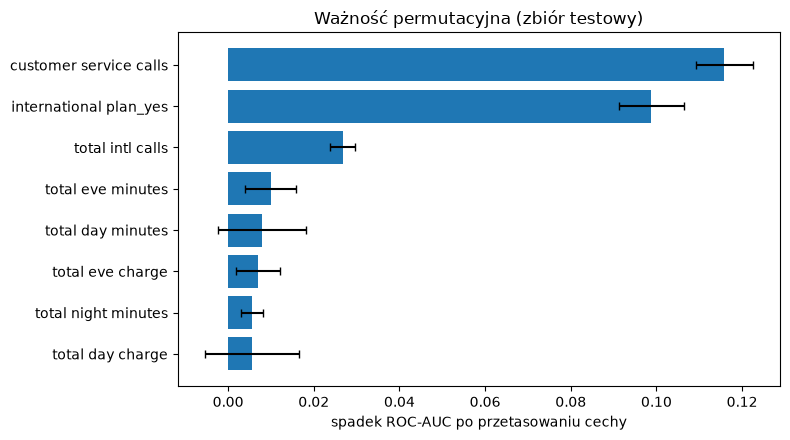

In [5]:
wynik_perm = permutation_importance(model, X_test, y_test, scoring='roc_auc',
                                    n_repeats=10, random_state=42, n_jobs=-1)

waznosc_perm = pd.DataFrame({'średni spadek AUC': wynik_perm.importances_mean,
                             'odchylenie': wynik_perm.importances_std},
                            index=X.columns).sort_values('średni spadek AUC', ascending=False)

top = waznosc_perm.head(8).iloc[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.index, top['średni spadek AUC'], xerr=top['odchylenie'], capsize=3)
plt.xlabel('spadek ROC-AUC po przetasowaniu cechy')
plt.title('Ważność permutacyjna (zbiór testowy)')
plt.tight_layout()
plt.show()

Wynik wyraźnie różni się od ważności z lasu: na czele są **`customer service calls`** i **`international plan_yes`**, a `total day minutes` i `total day charge` spadły daleko w dół. Dlaczego? Gdy tasujemy `total day minutes`, model nadal ma `total day charge` z tą samą informacją i prawie nic nie traci. **Cechy skorelowane „zasłaniają się” nawzajem**, więc permutacja każdej z nich osobno zaniża ich ważność. To najważniejsza pułapka tej metody (punkt 11).

Porównajmy pozycje cech w obu rankingach:

In [6]:
porownanie = pd.DataFrame({
    'pozycja: ważność z lasu': waznosc_lasu.rank(ascending=False),
    'pozycja: ważność permutacyjna': waznosc_perm['średni spadek AUC'].rank(ascending=False),
}).astype(int).sort_values('pozycja: ważność permutacyjna')

porownanie.head(8)

,pozycja: ważność z lasu,pozycja: ważność permutacyjna
customer service calls,3,1
international plan_yes,4,2
total intl calls,7,3
total eve minutes,5,4
total day minutes,1,5
total eve charge,6,6
total night minutes,10,7
total day charge,2,8


## 5. Wykresy częściowej zależności (PDP)

Ważność mówi, **które** cechy są istotne, ale nie **jak** wpływają. Odpowiada na to **PDP** (*Partial Dependence Plot*): dla kolejnych wartości jednej cechy (oś X) ustawiamy tę wartość **u wszystkich klientów** i liczymy **średnią predykcję** modelu (oś Y). Pokazuje więc, jak średnio zmienia się przewidywane prawdopodobieństwo odejścia, gdy zmieniamy tylko tę cechę.

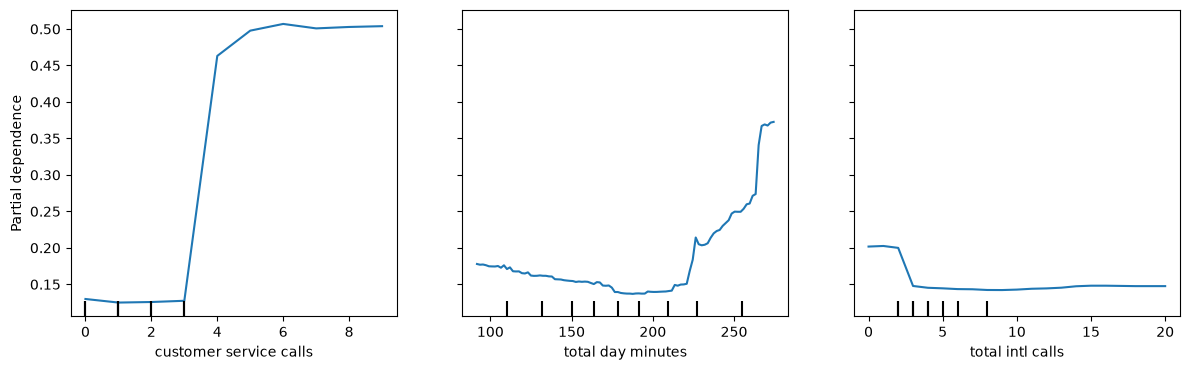

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.8))
PartialDependenceDisplay.from_estimator(
    model, X_test, ['customer service calls', 'total day minutes', 'total intl calls'], ax=ax)
plt.tight_layout()
plt.show()

Wnioski (liczby na osi Y to średnie prawdopodobieństwo odejścia):
- **`customer service calls`:** do 3 rozmów ryzyko jest niskie (ok. 0,13), od 4 rozmów **gwałtownie rośnie** (ok. 0,45–0,50) i dalej już się nie zmienia. To **próg**, a nie zależność liniowa – takiej zależności nie wychwyciłaby prosta regresja liniowa bez dodatkowych zabiegów.
- **`total day minutes`:** ryzyko jest najniższe przy ok. 150–200 minutach dziennie, a **rośnie dla klientów, którzy dużo rozmawiają** (powyżej ok. 215 minut).
- **`total intl calls`:** klienci z 0–2 rozmowami międzynarodowymi odchodzą nieco częściej.

Pionowe kreski przy osi X (*rug plot*) pokazują, gdzie leży większość danych – tam wykres jest wiarygodny; na krańcach, gdzie danych jest mało, jest niepewny.

## 6. SHAP – idea

**SHAP** (*SHapley Additive exPlanations*) wyjaśnia **pojedynczą predykcję**, dzieląc ją między cechy. Pomysł pochodzi z teorii gier: cechy to „gracze” w drużynie, a predykcja to „wspólna wypłata”. Wartość SHAP cechy to jej **sprawiedliwy udział** w różnicy między predykcją dla danego klienta a **predykcją średnią** (liczony jako średni wkład cechy po wszystkich możliwych kolejnościach dołączania cech).

Najważniejsza własność (*addytywność*):

$$\text{predykcja dla klienta} = \text{wartość bazowa} + \sum_{j} \text{SHAP}_j$$

- **wartość bazowa** to średnia predykcja modelu (tu: średnie prawdopodobieństwo odejścia),
- **SHAP > 0** – cecha **zwiększa** predykcję (w tym przykładzie: zwiększa ryzyko odejścia),
- **SHAP < 0** – cecha ją **zmniejsza**.

Dla modeli drzewiastych używamy szybkiego i dokładnego `TreeExplainer`. Wywołanie go na danych zwraca obiekt `Explanation`. Dla klasyfikacji wartości SHAP są liczone **osobno dla każdej klasy**, a nas interesuje klasa 1 (odejście).

In [8]:
explainer = shap.TreeExplainer(model)
wyjasnienie = explainer(X_test)

print('Kształt wartości SHAP (klienci, cechy, klasy):', wyjasnienie.values.shape)

# interesuje nas klasa 1 (klient odchodzi)
shap_odejscie = wyjasnienie[:, :, 1]
print('Wartość bazowa (średnie prawdopodobieństwo odejścia):', shap_odejscie.base_values[0].round(3))

Kształt wartości SHAP (klienci, cechy, klasy): (834, 17, 2)
Wartość bazowa (średnie prawdopodobieństwo odejścia): 0.145


Sprawdźmy addytywność na własne oczy: wartość bazowa plus suma wartości SHAP wszystkich cech powinna dać dokładnie `predict_proba` modelu.

In [9]:
odtworzona = shap_odejscie.base_values + shap_odejscie.values.sum(axis=1)

print('Największa różnica |wartość bazowa + suma SHAP - predict_proba|:', np.abs(odtworzona - proba).max())
print('Pierwsze 5 klientów, predict_proba      :', proba[:5].round(3))
print('Pierwsze 5 klientów, baza + suma SHAP   :', odtworzona[:5].round(3))

Największa różnica |wartość bazowa + suma SHAP - predict_proba|: 5.0411064211886014e-15
Pierwsze 5 klientów, predict_proba      : [0.017 0.017 0.27  0.277 0.073]
Pierwsze 5 klientów, baza + suma SHAP   : [0.017 0.017 0.27  0.277 0.073]


## 7. SHAP – interpretacja globalna

Mając wartości SHAP dla **wszystkich** klientów, możemy je zagregować. Wykres słupkowy pokazuje **średnią wartość bezwzględną SHAP** każdej cechy, czyli przeciętny wpływ cechy na predykcję (w jednostkach prawdopodobieństwa).

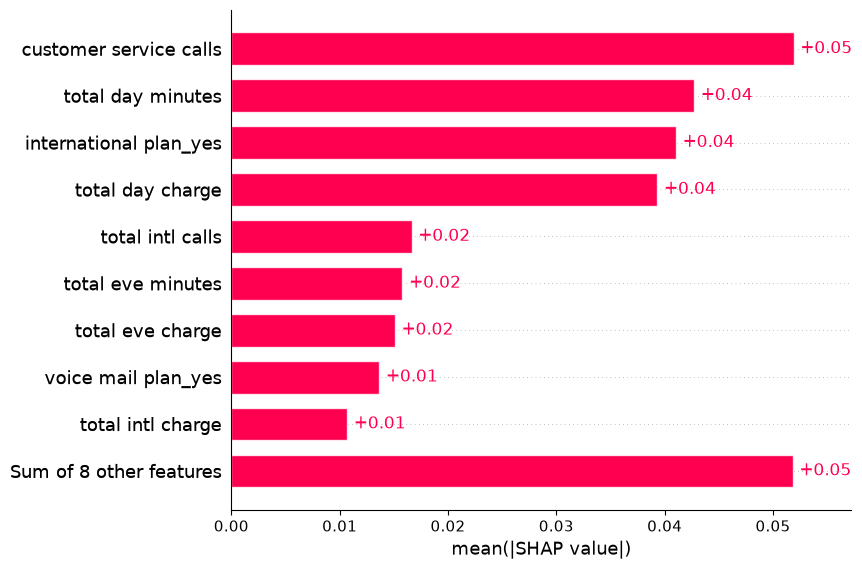

In [10]:
shap.plots.bar(shap_odejscie)

Wykres typu **beeswarm** pokazuje więcej: każdy punkt to **jeden klient**, położenie na osi X to wartość SHAP (w prawo – zwiększa ryzyko odejścia, w lewo – zmniejsza), a kolor to **wartość cechy** (czerwony – wysoka, niebieski – niska).

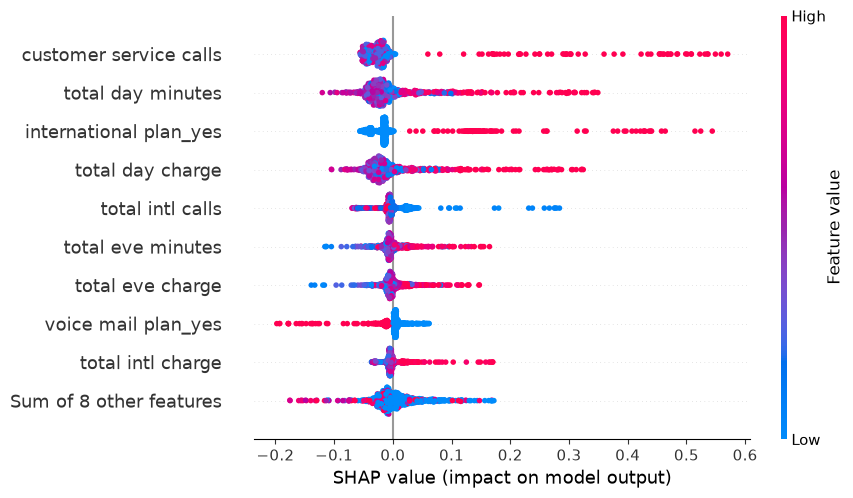

In [11]:
shap.plots.beeswarm(shap_odejscie)

Jak to czytać (wiersze od góry):
- **`customer service calls`:** czerwone punkty (dużo rozmów z obsługą) leżą **po prawej** – zwiększają ryzyko odejścia, często mocno (nawet o 0,5). Niebieskie (mało rozmów) są blisko zera.
- **`total day minutes`:** wysokie wartości (czerwone) przesuwają predykcję w prawo, niskie – lekko w lewo.
- **`international plan_yes`:** klienci z planem międzynarodowym (czerwone punkty, wartość 1) mają zwiększone ryzyko odejścia.
- **`total intl calls`:** odwrotnie niż zwykle – **niskie** wartości (niebieskie) leżą po prawej, czyli mało rozmów międzynarodowych zwiększa ryzyko.
- **`voice mail plan_yes`:** czerwone punkty (klient ma pocztę głosową) leżą po lewej, więc poczta głosowa **zmniejsza** ryzyko.

Zwróćmy uwagę, że to samo, co pokazało PDP (próg przy `customer service calls`, rosnące ryzyko dla dużej liczby minut), widać tu na poziomie **pojedynczych klientów**. Podobnie jak ranking permutacyjny, SHAP stawia na czele `customer service calls` i `international plan_yes`, ale `total day minutes` i `total day charge` pozostają wysoko: dla cech niosących tę samą informację SHAP **dzieli wkład** między nie, zamiast go zaniżać. W odróżnieniu od ważności permutacyjnej SHAP pokazuje także **kierunek** wpływu.

## 8. SHAP – interpretacja lokalna (pojedynczy klient)

Na wykresie **waterfall** (wodospad) widzimy, jak od wartości bazowej dochodzimy do predykcji dla **jednego** klienta. Każda strzałka to wkład jednej cechy: czerwona zwiększa ryzyko odejścia, niebieska je zmniejsza. Przy nazwie cechy podana jest **wartość tej cechy u tego klienta**.

Zacznijmy od klienta, któremu model przypisał **najwyższe** prawdopodobieństwo odejścia.

Klient nr 561 w zbiorze testowym: prawdopodobieństwo odejścia 0.99, faktycznie odszedł


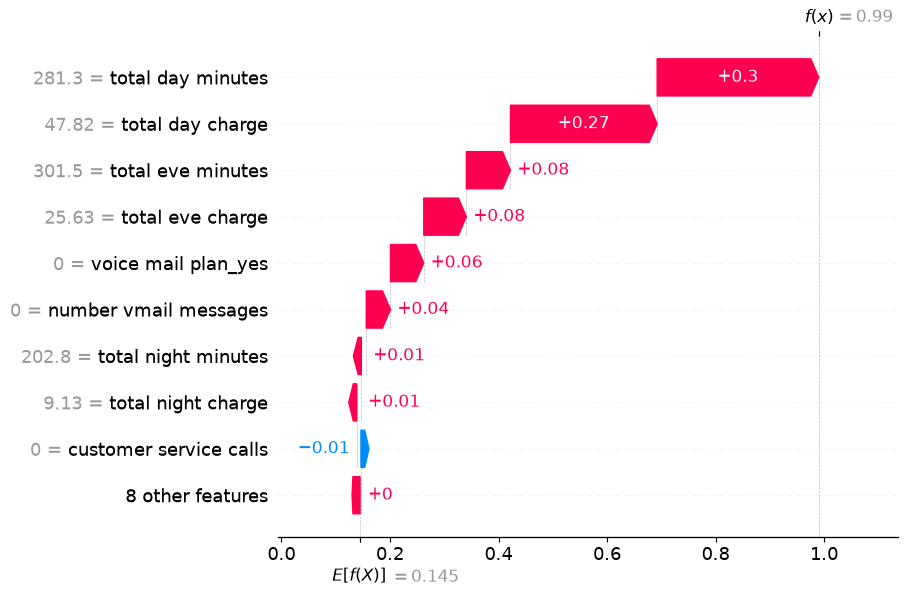

In [12]:
i_ryzyko = int(np.argmax(proba))

print(f'Klient nr {i_ryzyko} w zbiorze testowym: prawdopodobieństwo odejścia {proba[i_ryzyko]:.2f}, '
      f'faktycznie {"odszedł" if y_test.iloc[i_ryzyko] == 1 else "został"}')

shap.plots.waterfall(shap_odejscie[i_ryzyko])

Czytamy od dołu: start to wartość bazowa `E[f(X)]` (ok. 0,145), a każda cecha przesuwa wynik w prawo lub w lewo, aż do końcowej predykcji `f(x)`. Największy wkład mają tu **`total day minutes`** i **`total day charge`** (281 minut i 47,8 opłaty, czyli wartości bardzo wysokie), dalej wysokie rozmowy wieczorne (`total eve minutes`, `total eve charge`) i brak poczty głosowej. Ponieważ minuty i opłata niosą tę samą informację, ich wkład jest „podzielony” na dwie cechy. Warto zauważyć, że ten klient ma **0 rozmów z obsługą** (wkład ok. −0,01), a mimo to model jest prawie pewien jego odejścia: przesądza intensywne korzystanie z usług.

Dla kontrastu spójrzmy na klienta z **niepewną** predykcją, blisko progu 0,5:

Klient nr 299 w zbiorze testowym: prawdopodobieństwo odejścia 0.50, faktycznie odszedł


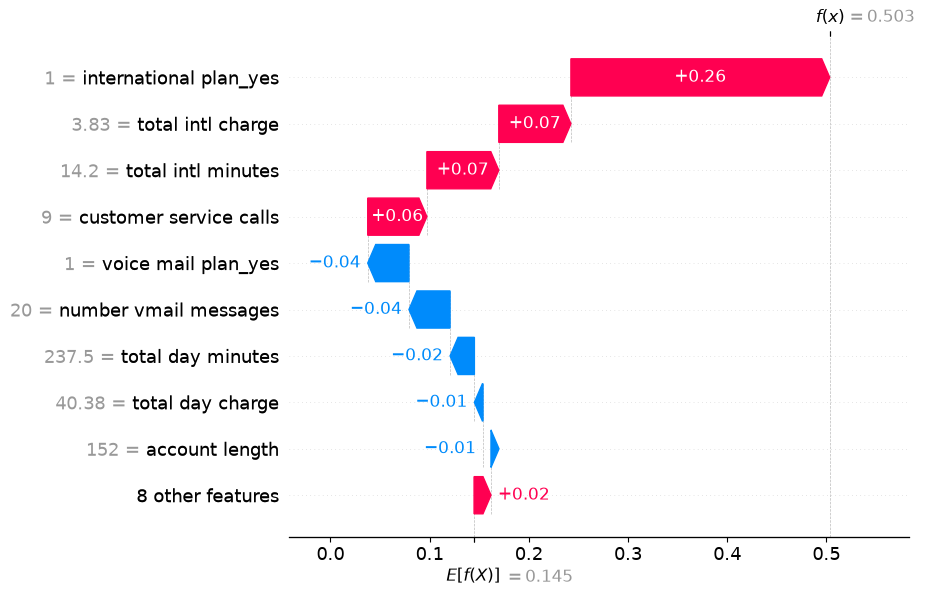

In [13]:
i_niepewny = int(np.argmin(np.abs(proba - 0.5)))

print(f'Klient nr {i_niepewny} w zbiorze testowym: prawdopodobieństwo odejścia {proba[i_niepewny]:.2f}, '
      f'faktycznie {"odszedł" if y_test.iloc[i_niepewny] == 1 else "został"}')

shap.plots.waterfall(shap_odejscie[i_niepewny])

Tu obraz jest inny: najsilniej zwiększa ryzyko **plan międzynarodowy** (`international plan_yes` = 1, wkład ok. +0,26), a dokładają się do tego wysoki czas i opłata za rozmowy międzynarodowe oraz 9 rozmów z obsługą (+0,06). Przeciwnie działa m.in. **poczta głosowa** (niebieskie strzałki: `voice mail plan_yes`, `number vmail messages`), która zmniejsza ryzyko. Wynik 0,50 jest więc **bilansem** czynników zwiększających i zmniejszających ryzyko.

Zauważmy też, że 9 rozmów z obsługą dodaje tu tylko +0,06, choć u innych klientów ta cecha potrafiła dawać znacznie więcej (beeswarm). Wkład cechy zależy od **kontekstu**, czyli od wartości pozostałych cech u danego klienta.

## 9. LIME – alternatywne wyjaśnienie lokalne

**LIME** (*Local Interpretable Model-agnostic Explanations*) działa inaczej niż SHAP:
1. bierze jednego klienta i **tworzy wokół niego wiele „sztucznych” klientów** (lekko zmieniając wartości cech),
2. **pyta model** o predykcję dla każdego z nich,
3. dopasowuje **prosty model liniowy**, który w tym najbliższym otoczeniu naśladuje złożony model (bliższe obserwacje mają większą wagę),
4. współczynniki tego prostego modelu to wyjaśnienie.

LIME działa dla dowolnego modelu, wystarczy funkcja zwracająca prawdopodobieństwa. Wyjaśnimy tego samego klienta co w SHAP (z najwyższym ryzykiem).

international plan_yes <= 0.00      -0.219
total day charge > 36.70            +0.100
total day minutes > 215.90          +0.097
customer service calls <= 1.00      -0.071
total eve minutes > 234.25          +0.053
total eve charge > 19.91            +0.044
voice mail plan_yes <= 0.00         +0.038
total intl calls <= 3.00            +0.035


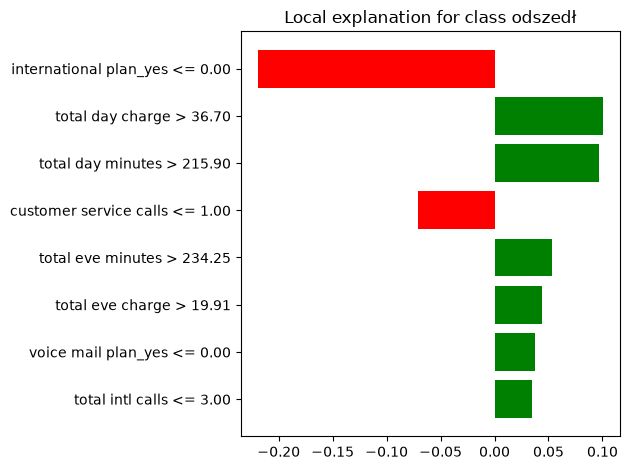

In [14]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X.columns),
    class_names=['został', 'odszedł'],
    mode='classification',
    random_state=42,
)

def predict_proba_df(tablica):
    # LIME podaje tablicę NumPy, a model był uczony na DataFrame z nazwami kolumn
    return model.predict_proba(pd.DataFrame(tablica, columns=X.columns))

wyjasnienie_lime = lime_explainer.explain_instance(
    X_test.iloc[i_ryzyko].values, predict_proba_df, num_features=8)

for opis, waga in wyjasnienie_lime.as_list():
    print(f'{opis:35s} {waga:+.3f}')

fig = wyjasnienie_lime.as_pyplot_figure()
fig.tight_layout()
plt.show()

Jak czytać wynik: waga **dodatnia** (zielony słupek) oznacza, że warunek zwiększa prawdopodobieństwo odejścia, **ujemna** (czerwony) – że je zmniejsza. LIME dzieli cechy ciągłe na przedziały (kwartyle), stąd opisy typu `total day charge > 36.70` (górny kwartyl).

Obie metody zgadzają się co do głównych sił: wysokie `total day minutes` i `total day charge` oraz wysokie rozmowy wieczorne **zwiększają** ryzyko (LIME: ok. +0,10 dla każdej z dwóch pierwszych cech). Są też różnice: LIME przypisuje największą wagę (ok. −0,22) temu, że klient **nie ma** planu międzynarodowego, a według SHAP wkład tej cechy jest pomijalny (poniżej 0,01 co do wartości bezwzględnej). Wynika to m.in. z różnych punktów odniesienia: LIME porównuje klienta z losowo „zaburzonymi” klientami z otoczenia (wśród nich są i tacy z planem), a SHAP z przeciętną predykcją modelu. LIME losuje sztucznych klientów, dlatego ustawiamy `random_state`, żeby wynik był powtarzalny.

## 10. XAI jako narzędzie do wykrywania błędów

W rozdziale 4.4 poznaliśmy **wyciek danych** (*data leakage*): do cech trafia informacja, której nie mielibyśmy w chwili przewidywania. Model z wyciekiem ma **podejrzanie dobry wynik**, a metody XAI pomagają znaleźć winowajcę. Zasymulujmy to: dodajemy cechę `status_po_rezygnacji`, która w 95% przypadków pokrywa się z `churn` (jakby ktoś zapisał ją w systemie dopiero **po** odejściu klienta).

In [15]:
rng = np.random.default_rng(42)
X_wyciek = X.copy()
X_wyciek['status_po_rezygnacji'] = np.where(rng.random(len(y)) < 0.95, y, 1 - y).astype(float)

Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_wyciek, y, test_size=0.25, random_state=42, stratify=y)

model_wyciek = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xw_train, yw_train)
print(f'ROC-AUC: {roc_auc_score(yw_test, model_wyciek.predict_proba(Xw_test)[:, 1]):.3f}  '
      f'(bez wycieku: {roc_auc_score(y_test, proba):.3f})')

perm_wyciek = permutation_importance(model_wyciek, Xw_test, yw_test, scoring='roc_auc',
                                     n_repeats=5, random_state=42, n_jobs=-1)
pd.Series(perm_wyciek.importances_mean, index=X_wyciek.columns).sort_values(ascending=False).head(4).round(3)

ROC-AUC: 0.991  (bez wycieku: 0.898)


status_po_rezygnacji      0.186
international plan_yes    0.013
customer service calls    0.011
total day minutes         0.005
dtype: float64

Wynik **rośnie** z 0,90 do 0,99, a ważność permutacyjna wskazuje jedną cechę (`status_po_rezygnacji`) ważniejszą od wszystkich pozostałych razem wziętych. To klasyczny **sygnał ostrzegawczy**: zbyt dobry wynik i jedna dominująca cecha. Pytamy wtedy: czy ta informacja będzie dostępna w chwili, gdy model ma przewidywać? Jeśli nie, cechę trzeba usunąć. Tak właśnie XAI pomaga wychwycić błędy, zanim model trafi do użytku.

## 11. Pułapki i dobre praktyki

1. **Wyjaśniamy model, nie rzeczywistość.** Ważność, PDP i SHAP mówią, **na czym polega model**, a nie jak działa świat. Jeśli model nauczył się błędnej zależności, wyjaśnienie pokaże właśnie ją.
2. **Korelacja to nie przyczynowość.** Wiele rozmów z obsługą wiąże się z odejściem klienta, ale to raczej **objaw** niezadowolenia niż jego przyczyna. Ograniczenie liczby rozmów nie sprawi, że klienci zostaną.
3. **Cechy skorelowane utrudniają interpretację** (punkty 3 i 4): ważność dzieli się między nie lub jest zaniżana. Przed interpretacją warto usunąć lub połączyć cechy niosące tę samą informację.
4. **Wyjaśnienia liczymy na danych testowych** (lub walidacyjnych), a nie na treningowych, na których model mógł się przeuczyć.
5. **Różne metody mogą dawać różne odpowiedzi** (np. LIME i SHAP w punkcie 9). Rozbieżność jest sygnałem, by przyjrzeć się danym, a nie dowodem, że któraś metoda „kłamie”.
6. **Koszt obliczeń:** SHAP dla dużych modeli i zbiorów może być wolny (próbkowanie wierszy, `shap.sample`); permutacja wymaga wielokrotnego liczenia predykcji.
7. **Wyjaśnialność nie zastępuje walidacji.** Dobre wyjaśnienie złego modelu nie czyni go dobrym.
8. Metody z tego notatnika działają **tak samo dla regresji** (np. dla modeli z rozdziału 3.1): zamiast spadku AUC używamy spadku R², a wartości SHAP są w jednostkach zmiennej docelowej.

## 12. Podsumowanie

1. Złożone modele (las, boosting, sieci) to czarne skrzynki; **XAI** pozwala je zrozumieć, wykryć błędy i uzasadnić decyzje.
2. Wyjaśnienia dzielimy na **globalne** (co ważne w ogóle) i **lokalne** (dlaczego ta jedna decyzja).
3. **`feature_importances_`** jest szybkie, ale bywa mylące; **ważność permutacyjna** liczona na zbiorze testowym jest rzetelniejsza, lecz zaniża cechy skorelowane.
4. **PDP** pokazuje, **jak** średnio zmienia się predykcja wraz z wartością cechy (np. progi).
5. **SHAP** rozkłada predykcję na wkłady cech: `wartość bazowa + suma SHAP = predykcja`. Daje wyjaśnienia globalne (bar, beeswarm) i lokalne (waterfall) oraz **kierunek** wpływu.
6. **LIME** buduje prosty model w otoczeniu jednej obserwacji; jest intuicyjny, ale opiera się na losowaniu i może dawać inne wnioski niż SHAP.
7. XAI pomaga wykrywać **wyciek danych** i inne błędy, ale pokazuje zależności w modelu, **nie przyczyny** w rzeczywistości.

| Metoda | Zakres | Kierunek wpływu | Uwagi |
|---|---|---|---|
| `feature_importances_` | globalna | nie | tylko modele drzewiaste, liczone na treningu |
| ważność permutacyjna | globalna | nie | dowolny model; zaniża cechy skorelowane |
| PDP | globalna | tak | pokazuje kształt zależności (progi, monotoniczność) |
| SHAP | globalna i lokalna | tak | spójna teoria, szybki dla drzew |
| LIME | lokalna | tak | dowolny model; wynik zależy od losowania (ustaw `random_state`) |